# Density versus temperature

Publication-style density panel. It uses direct labels instead of a legend and only reads compact chapter data.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

candidates = [Path.cwd(), Path.cwd() / '01_density', Path.cwd().parent]
chapter = next(path for path in candidates if (path / 'data/density_vs_temperature.csv').is_file())
simulation = np.genfromtxt(chapter / 'data/density_vs_temperature.csv', delimiter=',', names=True, dtype=None, encoding='utf-8')
tokuda_digitized = np.genfromtxt(chapter / 'reference_data/tokuda_density.csv', delimiter=',', names=True)


/home/akryachkova/ams2025.106/bin/python3.8/lib/python3.8/site-packages/mpl_toolkits/__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __import__('pkg_resources').declare_namespace(__name__)


/home/akryachkova/.conda/envs/so3lr312/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


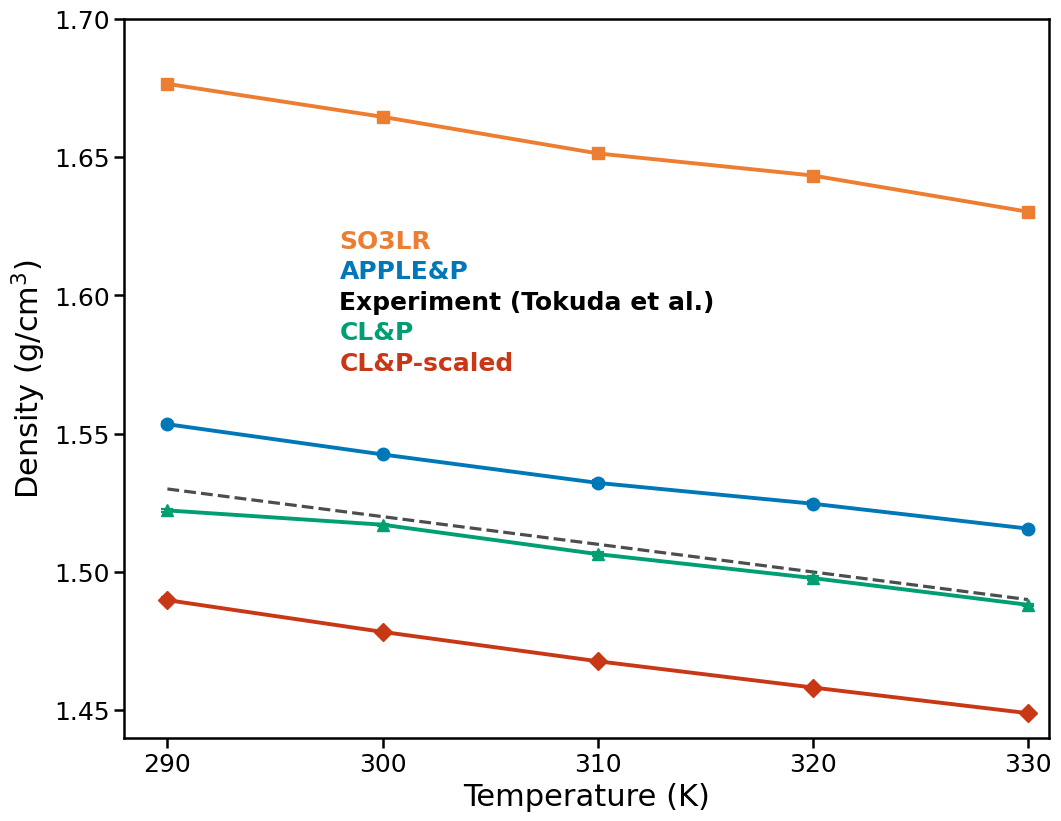

In [2]:
# Model names in the stored CSV are translated only for display.
display_name = {'OPLS': 'CL&P', 'OPLS-scaled': 'CL&P-scaled'}
styles = {
    'SO3LR': {'color': '#ed7d31', 'marker': 's'},
    'APPLE&P': {'color': '#0078b8', 'marker': 'o'},
    'OPLS': {'color': '#009e73', 'marker': '^'},
    'OPLS-scaled': {'color': '#c83817', 'marker': 'D'},
}

# The current figure and digitized Tokuda points are consistent with
# rho = 1.82 - T_kK, where T_kK is temperature in 1000 K.
temperature_K = np.arange(290.0, 331.0, 10.0)
tokuda_rho = 1.82 - temperature_K / 1000.0

plt.rcParams.update({'font.family': 'DejaVu Sans'})
fig, ax = plt.subplots(figsize=(10.5, 8.1), constrained_layout=True)

for force_field in ('SO3LR', 'APPLE&P', 'OPLS', 'OPLS-scaled'):
    rows = simulation[simulation['force_field'] == force_field]
    ax.errorbar(rows['temperature_K'], rows['density_g_cm3'], yerr=rows['density_sem_g_cm3'],
                color=styles[force_field]['color'], marker=styles[force_field]['marker'],
                lw=2.8, ms=9, capsize=4, capthick=1.6, elinewidth=1.6, zorder=3)

ax.plot(temperature_K, tokuda_rho, color='#4d4d4d', lw=2.3, ls='--', zorder=2)

# Direct on-panel labels.
label_x = 298.0
for text, y, color in [
    ('SO3LR', 1.617, styles['SO3LR']['color']),
    ('APPLE&P', 1.606, styles['APPLE&P']['color']),
    ('Experiment (Tokuda et al.)', 1.595, 'black'),
    ('CL&P', 1.584, styles['OPLS']['color']),
    ('CL&P-scaled', 1.573, styles['OPLS-scaled']['color']),
]:
    ax.text(label_x, y, text, color=color, fontsize=18, fontweight='bold', ha='left')

ax.set_xlim(288, 331)
ax.set_ylim(1.44, 1.70)
ax.set_xticks(np.arange(290, 331, 10))
ax.set_xlabel('Temperature (K)', fontsize=22)
ax.set_ylabel(r'Density (g/cm$^3$)', fontsize=22)
ax.tick_params(axis='both', which='major', labelsize=18, width=1.8, length=7)
for spine in ax.spines.values():
    spine.set_linewidth(1.8)

# Visual cross-check only: the original digitized Tokuda points should track the line.
assert np.max(np.abs((1.82 - tokuda_digitized['temperature_K'] / 1000.0) - tokuda_digitized['density_g_cm3'])) < 0.006
(chapter / 'figures').mkdir(exist_ok=True)
fig.savefig(chapter / 'figures/density.png', dpi=300, bbox_inches='tight')
plt.show()
